In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 30)

print("Imports successful.")

Imports successful.


In [3]:
files = sorted(Path("../data").rglob("*.csv"))

for file in files:
    print(file)

../data/SkillCraft1_Dataset.csv
../data/dota2Test.csv
../data/dota2Train.csv


In [4]:
raw_train = pd.read_csv("../data/dota2Train.csv", header=None)
raw_test = pd.read_csv("../data/dota2Test.csv", header=None)

print("Train shape:", raw_train.shape)
print("Test shape:", raw_test.shape)
print("Total matches:", len(raw_train) + len(raw_test))

raw_train.iloc[:5, :12]

Train shape: (92650, 117)
Test shape: (10294, 117)
Total matches: 102944


,0,1,2,3,4,5,6,7,8,9,10,11
0,-1,223,2,2,0,0,0,0,0,0,0,0
1,1,152,2,2,0,0,0,1,0,-1,0,0
2,1,131,2,2,0,0,0,1,0,-1,0,0
3,1,154,2,2,0,0,0,0,0,0,-1,0
4,-1,171,2,3,0,0,0,0,0,-1,0,0


In [5]:
columns = (
    ["win", "clusterid", "gamemode", "gametype"]
    + [f"hero_{i}" for i in range(1, 114)]
)

print("Number of column names:", len(columns))

train = raw_train.copy()
test = raw_test.copy()

train.columns = columns
test.columns = columns

train.iloc[:5, :12]

Number of column names: 117


,win,clusterid,gamemode,gametype,hero_1,hero_2,hero_3,hero_4,hero_5,hero_6,hero_7,hero_8
0,-1,223,2,2,0,0,0,0,0,0,0,0
1,1,152,2,2,0,0,0,1,0,-1,0,0
2,1,131,2,2,0,0,0,1,0,-1,0,0
3,1,154,2,2,0,0,0,0,0,0,-1,0
4,-1,171,2,3,0,0,0,0,0,-1,0,0


In [6]:
print("WIN VALUES:")
print(train["win"].value_counts().sort_index())

print("\nGAME MODE VALUES:")
print(train["gamemode"].value_counts().sort_index())

print("\nGAME TYPE VALUES:")
print(train["gametype"].value_counts().sort_index())

print("\nNUMBER OF CLUSTERS:")
print(train["clusterid"].nunique())

print("\nMISSING VALUES:")
print(train.isna().sum().sum())

WIN VALUES:
win
-1    43868
 1    48782
Name: count, dtype: int64

GAME MODE VALUES:
gamemode
1     1229
2    71897
3      386
4      208
5       12
6      498
7       81
8     8306
9    10033
Name: count, dtype: int64

GAME TYPE VALUES:
gametype
1       15
2    56988
3    35647
Name: count, dtype: int64

NUMBER OF CLUSTERS:
47

MISSING VALUES:
0


In [7]:
hero_cols = [f"hero_{i}" for i in range(1, 114)]

# What values occur in the hero columns?
hero_values = np.unique(train[hero_cols].values)

print("Unique hero values:")
print(hero_values)

# How many heroes are selected in each match?
selected_per_match = (train[hero_cols] != 0).sum(axis=1)

print("\nNumber of selected heroes per match:")
print(selected_per_match.value_counts().sort_index())

# How many heroes belong to each team?
team1_per_match = (train[hero_cols] == 1).sum(axis=1)
team2_per_match = (train[hero_cols] == -1).sum(axis=1)

print("\nTeam 1 hero counts:")
print(team1_per_match.value_counts().sort_index())

print("\nTeam 2 hero counts:")
print(team2_per_match.value_counts().sort_index())

Unique hero values:
[-1  0  1]

Number of selected heroes per match:
10    92650
Name: count, dtype: int64

Team 1 hero counts:
5    92650
Name: count, dtype: int64

Team 2 hero counts:
5    92650
Name: count, dtype: int64


In [9]:
total_hero_cells = train[hero_cols].size
zero_hero_cells = (train[hero_cols] == 0).sum().sum()

sparsity = zero_hero_cells / total_hero_cells * 100

print("Total hero cells:", total_hero_cells)
print("Zero-valued hero cells:", zero_hero_cells)
print(f"Sparsity: {sparsity:.2f}%")

Total hero cells: 10469450
Zero-valued hero cells: 9542950
Sparsity: 91.15%


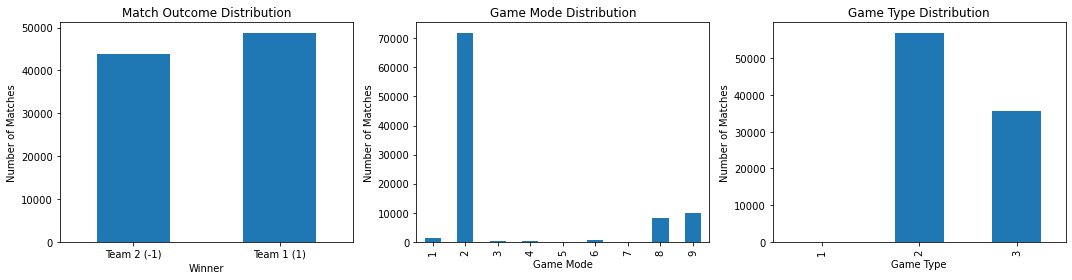

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Win distribution
train["win"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[0]
)
axes[0].set_title("Match Outcome Distribution")
axes[0].set_xlabel("Winner")
axes[0].set_ylabel("Number of Matches")
axes[0].set_xticklabels(["Team 2 (-1)", "Team 1 (1)"], rotation=0)

# 2. Game mode distribution
train["gamemode"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[1]
)
axes[1].set_title("Game Mode Distribution")
axes[1].set_xlabel("Game Mode")
axes[1].set_ylabel("Number of Matches")

# 3. Game type distribution
train["gametype"].value_counts().sort_index().plot(
    kind="bar",
    ax=axes[2]
)
axes[2].set_title("Game Type Distribution")
axes[2].set_xlabel("Game Type")
axes[2].set_ylabel("Number of Matches")

plt.tight_layout()
plt.savefig("../figures/dota2_match_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
hero_usage = (train[hero_cols] != 0).sum().sort_values(ascending=False)

print("15 most frequently selected heroes:")
print(hero_usage.head(15))

15 most frequently selected heroes:
hero_9      32048
hero_44     29802
hero_14     28285
hero_104    26521
hero_8      23327
hero_93     23125
hero_6      21700
hero_74     21262
hero_2      20264
hero_32     19670
hero_35     17276
hero_98     17155
hero_18     17029
hero_41     16746
hero_1      14973
dtype: int64


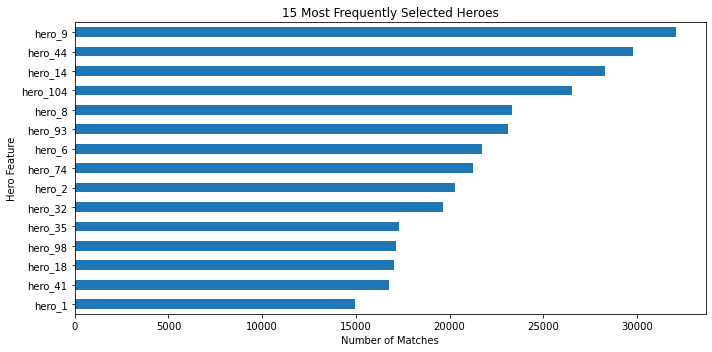

In [13]:
top15 = hero_usage.head(15)

plt.figure(figsize=(10, 5))
top15.sort_values().plot(kind="barh")

plt.title("15 Most Frequently Selected Heroes")
plt.xlabel("Number of Matches")
plt.ylabel("Hero Feature")

plt.tight_layout()
plt.savefig("../figures/dota2_top15_hero_usage.png", dpi=150, bbox_inches="tight")
plt.show()